# Naive Bayes

In [5]:
import numpy as np
import pandas as pd

from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.model_selection import KFold,GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc

import matplotlib.pyplot as plt

In [6]:

df = pd.read_csv("Covid Dataset.csv")
df1 = df.dropna()
df1.head()

,Breathing Problem,Fever,Dry Cough,Sore throat,Running Nose,Asthma,Chronic Lung Disease,Headache,Heart Disease,Diabetes,...,Fatigue,Gastrointestinal,Abroad travel,Contact with COVID Patient,Attended Large Gathering,Visited Public Exposed Places,Family working in Public Exposed Places,Wearing Masks,Sanitization from Market,COVID-19
0,Yes,Yes,Yes,Yes,Yes,No,No,No,No,Yes,...,Yes,Yes,No,Yes,No,Yes,Yes,No,No,Yes
1,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,No,No,...,Yes,No,No,No,Yes,Yes,No,No,No,Yes
2,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,...,Yes,Yes,Yes,No,No,No,No,No,No,Yes
3,Yes,Yes,Yes,No,No,Yes,No,No,Yes,Yes,...,No,No,Yes,No,Yes,Yes,No,No,No,Yes
4,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,...,No,Yes,No,Yes,No,Yes,No,No,No,Yes


In [7]:

for i in df1.columns:
    df1[i] = df1[i].apply(lambda x: 1 if x == "Yes" else 0)

df1.head()

,Breathing Problem,Fever,Dry Cough,Sore throat,Running Nose,Asthma,Chronic Lung Disease,Headache,Heart Disease,Diabetes,...,Fatigue,Gastrointestinal,Abroad travel,Contact with COVID Patient,Attended Large Gathering,Visited Public Exposed Places,Family working in Public Exposed Places,Wearing Masks,Sanitization from Market,COVID-19
0,1,1,1,1,1,0,0,0,0,1,...,1,1,0,1,0,1,1,0,0,1
1,1,1,1,1,0,1,1,1,0,0,...,1,0,0,0,1,1,0,0,0,1
2,1,1,1,1,1,1,1,1,0,1,...,1,1,1,0,0,0,0,0,0,1
3,1,1,1,0,0,1,0,0,1,1,...,0,0,1,0,1,1,0,0,0,1
4,1,1,1,1,1,0,1,1,1,1,...,0,1,0,1,0,1,0,0,0,1


In [8]:

Y = df1["COVID-19"]
X = df1.drop("COVID-19", axis=1) 

## Gaussian Naive Bayes (Directly using KFold)

In [9]:
model = GaussianNB()

# Use KFold for cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = []

for train_index, test_index in kf.split(X):
    # Split data into training and testing sets
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    Y_train, Y_test = Y.iloc[train_index], Y.iloc[test_index]
    
    # Train the model
    model.fit(X_train, Y_train)
    
    # Test the model
    predictions = model.predict(X_test)
    
    acc = round(accuracy_score(Y_test, predictions),4)
    accuracy_scores.append(acc)


print(f"Accuracy per fold: {accuracy_scores}")

print("\nAverage accuracy:", np.mean(accuracy_scores))



Accuracy per fold: [0.7663, 0.7341, 0.7489, 0.7884, 0.7643]

Average accuracy: 0.7604


## Bernoulli Naive Bayes

In [10]:

model1 = BernoulliNB()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []

for train_index, test_index in kf.split(X):
  
    X_train1, X_test1 = X.iloc[train_index], X.iloc[test_index]
    Y_train1, Y_test1 = Y.iloc[train_index], Y.iloc[test_index]
    
    model1.fit(X_train1, Y_train1)
    predictions = model1.predict(X_test1)
    
    acc = round(accuracy_score(Y_test1, predictions),4)
    precision = round(precision_score(Y_test1, predictions),4)
    recall = round(recall_score(Y_test1, predictions),4)
    f1 = round(f1_score(Y_test1, predictions),4)
    
    accuracy_scores.append(acc)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

print("Accuracy per fold:", accuracy_scores)
print("Precision per fold:", precision_scores)
print("Recall per fold:", recall_scores)
print("F1-Score per fold:", f1_scores)

print("\nAverage Accuracy: {:.4f}".format(np.mean(accuracy_scores)))
print("Average Precision: {:.4f}".format(np.mean(precision_scores)))
print("Average Recall: {:.4f}".format(np.mean(recall_scores)))
print("Average F1-Score: {:.4f}".format(np.mean(f1_scores)))



Accuracy per fold: [0.9706, 0.9586, 0.9733, 0.9706, 0.9549]
Precision per fold: [0.9733, 0.9568, 0.9849, 0.9757, 0.966]
Recall per fold: [0.991, 0.9931, 0.9815, 0.9888, 0.9782]
F1-Score per fold: [0.9821, 0.9746, 0.9832, 0.9822, 0.9721]

Average Accuracy: 0.9656
Average Precision: 0.9713
Average Recall: 0.9865
Average F1-Score: 0.9788


### Evaluation

#### ROC、AUC

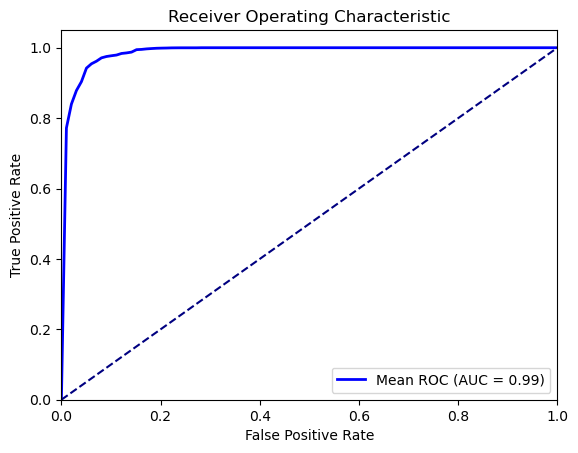

In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Initialize lists for FPR and TPR
tprs = []
mean_fpr = np.linspace(0, 1, 100)
roc_auc_list = []

for train_index, test_index in kf.split(X):
    
    X_train3, X_test3 = X.iloc[train_index], X.iloc[test_index]
    y_train3, y_test3 = Y.iloc[train_index], Y.iloc[test_index]
    
    model1.fit(X_train3, y_train3)
    
    # Predict probabilities for ROC curve
    y_test_proba = model1.predict_proba(X_test3)[:, 1]
    
    # Compute ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test3, y_test_proba)
    roc_auc = auc(fpr, tpr)
    roc_auc_list.append(roc_auc)
    
    # Interpolate TPR values for a common FPR range
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0  # Ensure the curve starts at (0,0)

# Calculate the mean TPR and its standard deviation
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0  # Ensure the curve ends at (1,1)
std_tpr = np.std(tprs, axis=0)

# Compute mean ROC AUC
mean_auc = np.mean(roc_auc_list)
std_auc = np.std(roc_auc_list)


# Plot the mean ROC curve
plt.figure()
plt.plot(mean_fpr, mean_tpr, color='b',label=r'Mean ROC (AUC = %0.2f)' % mean_auc
, lw=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')

#plot
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc='lower right')
plt.show()